### Build the target and features (the start of the ML)

In [2]:
#Load the clean orders

import sys
sys.path.append("..")
import numpy as np
import pandas as pd

df = pd.read_pickle("../data/orders_clean.pkl").sort_values("purchase_ts")
print(df.shape, df["purchase_ts"].max())

(97910, 27) 2018-08-29 15:00:37


In [3]:
#Take each customer’s first order
first = df.groupby("customer_unique_id").head(1).copy()
first = first.set_index("customer_unique_id")
print(len(first), "customers")

94707 customers


In [4]:
#Build the target. The target is 1 if the customer places a second order within 180 days of the first.
ranked = df.assign(order_rank=df.groupby("customer_unique_id").cumcount())
second_ts = ranked[ranked["order_rank"] == 1].set_index("customer_unique_id")["purchase_ts"]

first = df.groupby("customer_unique_id").head(1).copy().set_index("customer_unique_id")
first["second_ts"] = second_ts
first["days_to_second"] = (first["second_ts"] - first["purchase_ts"]).dt.days

# 1. Keep only customers with a full 180-day window
data_end = df["purchase_ts"].max()
first = first[first["purchase_ts"] <= data_end - pd.Timedelta(days=180)]

# 2. Drop same-day second orders (one shopping session split in two)
n_before = len(first)
first = first[first["days_to_second"] != 0]
print("dropped same-day second orders:", n_before - len(first))

# 3. Target: came back between day 1 and day 180
first["repeat_buyer"] = ((first["days_to_second"] >= 1) &
                         (first["days_to_second"] <= 180)).astype(int)

print(len(first), "customers")
print("repeat buyers:", first["repeat_buyer"].sum())
print("repeat rate:", round(first["repeat_buyer"].mean(), 4))

dropped same-day second orders: 718
56012 customers
repeat buyers: 1081
repeat rate: 0.0193


In [5]:
#Build features from the first order
f = pd.DataFrame(index=first.index)
f["items_value"]      = first["items_value"]
f["freight_value"]    = first["freight_value"]
f["freight_ratio"]    = first["freight_value"] / first["items_value"].replace(0, np.nan)
f["n_items"]          = first["n_items"]
f["payment_value"]    = first["payment_value"]
f["installments"]     = first["installments"]
f["delivery_days"]    = first["delivery_days"]
f["is_late"]          = first["is_late"]
f["review_score"]     = first["review_score"]
f["purchase_month"]   = first["purchase_ts"].dt.month
f["purchase_dow"]     = first["purchase_ts"].dt.day_of_week
f["payment_type"]     = first["payment_type"]
f["state"]            = first["state"]

# Group rare categories so the model doesn't see 70+ levels
top_cats = first["main_category"].value_counts().head(15).index
f["category"] = first["main_category"].where(first["main_category"].isin(top_cats), "other")

f["log_items_value"] = np.log1p(first["items_value"])
f["days_early"]      = (first["estimated_ts"] - first["delivered_ts"]).dt.total_seconds() / 86400
f["approval_hours"]  = (first["approved_ts"] - first["purchase_ts"]).dt.total_seconds() / 3600
f["n_sellers"]       = first["n_sellers"]
f["avg_weight_g"]    = first["avg_weight_g"]
f["avg_photos"]      = first["avg_photos"]
f["avg_desc_len"]    = first["avg_desc_len"]
f["n_payments"]      = first["n_payments"]
f["used_voucher"]    = first["used_voucher"]
f["has_comment"]     = first["has_comment"]
f["comment_len"]     = first["comment_len"]
f["black_friday"]    = first["purchase_ts"].between("2017-11-23", "2017-11-27").astype(int)

f["repeat_buyer"] = first["repeat_buyer"]
print(f.shape)
f.head()

(56012, 27)


,items_value,freight_value,freight_ratio,n_items,payment_value,installments,delivery_days,is_late,review_score,purchase_month,...,n_sellers,avg_weight_g,avg_photos,avg_desc_len,n_payments,used_voucher,has_comment,comment_len,black_friday,repeat_buyer
customer_unique_id,,,,,,,,,,,,,,,,,,,,,
f7b981e8a280e455ac3cbe0d5d171bd1,10.9,8.72,0.800000,1.0,19.62,1.0,6.054155,0.0,5.0,1,...,1.0,200.0,1.0,1710.0,1.0,0.0,1.0,152.0,0,0
da9c90677b1963eca1cf8a14c338cf6e,10.9,8.72,0.800000,1.0,19.62,1.0,11.165938,0.0,5.0,1,...,1.0,200.0,1.0,1710.0,1.0,0.0,1.0,77.0,0,0
ef89f6e31311594d74becf9e18c73693,11.9,8.72,0.732773,1.0,20.62,1.0,11.112187,0.0,5.0,1,...,1.0,200.0,2.0,2017.0,1.0,0.0,0.0,0.0,0,0
29a63a400c3ca9982907ce8de1f19527,10.9,8.72,0.800000,1.0,19.62,1.0,11.106933,0.0,5.0,1,...,1.0,200.0,1.0,1710.0,1.0,0.0,0.0,0.0,0,0
b6b2c3c8fd76769b478618a3c2505009,10.9,8.72,0.800000,1.0,19.62,1.0,11.095058,0.0,5.0,1,...,1.0,200.0,1.0,1710.0,1.0,0.0,1.0,53.0,0,0


In [6]:
#Check it and save it
print(f.isna().mean().round(3).sort_values(ascending=False).head(6))
print(f.groupby("is_late")["repeat_buyer"].mean().round(4))
print(f.groupby(f["review_score"].round())["repeat_buyer"].mean().round(4))
f.to_pickle("../data/model_data.pkl")

delivery_days    0.020
is_late          0.020
days_early       0.020
avg_photos       0.018
avg_desc_len     0.018
comment_len      0.008
dtype: float64
is_late
0.0    0.0197
1.0    0.0158
Name: repeat_buyer, dtype: float64
review_score
1.0    0.0159
2.0    0.0153
3.0    0.0186
4.0    0.0176
5.0    0.0210
Name: repeat_buyer, dtype: float64


In [7]:
print(first["days_to_second"].describe())
print((first["days_to_second"] == 0).sum(), "same-day second orders")
print((first["days_to_second"] <= 1).sum(), "second orders within 1 day")
print(first["repeat_buyer"].sum(), "total repeat buyers")

count    1565.000000
mean      136.144409
std       118.053684
min         1.000000
25%        35.000000
50%       109.000000
75%       206.000000
max       582.000000
Name: days_to_second, dtype: float64
0 same-day second orders
17 second orders within 1 day
1081 total repeat buyers


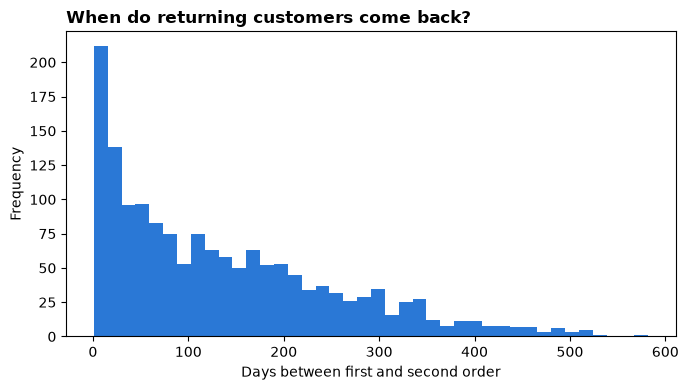

In [8]:
import matplotlib.pyplot as plt
ax = first["days_to_second"].dropna().plot.hist(bins=40, color="#2a78d6", figsize=(7, 4))
ax.set_xlabel("Days between first and second order")
ax.set_title("When do returning customers come back?", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/11_days_to_second_order.png", dpi=150, bbox_inches="tight")
plt.show()